In [2]:
from data_fetch import GetData
from engine import get_uniqueness_weights, generate_macro_dashboard
import numpy as np 
import pandas as pd
import yfinance as yf
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

ImportError: cannot import name 'GetData' from 'data_fetch' (/Users/leolombardini/Documents/CAPITALIS V2/src/macro_models/score macro engine/data_fetch.py)

In [ ]:

def get_historical_component_scores(data_map):
    regression_datasets = {}
    
    signs = {'CPI': 1, 'PMI': 1, 'Interest_Rate': 1, 'Unemployment': -1, 'Consumer_Sentiment': 1}
    halflife_map = {
        'CPI': 25,             # ~1 mois (jusqu'au prochain chiffre)
        'Interest_Rate': 40,   # ~1.5 mois (cycle des banques centrales)
        'Unemployment': 15,    # Intermédiaire
        'PMI': 5,              # Très court (Sentiment)
        'Consumer_Sentiment': 5
    }

    for zone, df in data_map.items():
        if df.empty: continue

        df_proc = df.copy().reset_index()
        if 'TimeStamp' not in df_proc.columns:
            df_proc.rename(columns={'index': 'TimeStamp', 'DATE': 'TimeStamp'}, inplace=True)        

        df_proc = df_proc.set_index('TimeStamp').resample('D').ffill().reset_index()
        
        weights = get_uniqueness_weights(df_proc) 
        deltas = df_proc['TimeStamp'].diff().dt.total_seconds().fillna(0) / 86400
        
        available_indicators = [c.replace('_Actual', '') for c in df_proc.columns if c.endswith('_Actual')]
        
        zone_components = pd.DataFrame(index=df_proc['TimeStamp'])

        for ind in available_indicators:
            col_act = f"{ind}_Actual"
            col_cons = f"{ind}_Consensus"
            
            # if col_cons not in df_proc.columns:
            #     df_proc[col_cons] = df_proc[col_act].shift(1)

            hl = halflife_map.get(ind, 10)
            lambda_ = np.log(2) / hl
            sign = signs.get(ind, 1)
            
            raw_shock = df_proc[col_act] - df_proc[col_cons]
            rolling_std = raw_shock.rolling(12).std().shift(1).replace(0, 1.0).fillna(1.0)
            norm_shock = (raw_shock / rolling_std).fillna(0)
            
            scores = np.zeros(len(df_proc))
            for t in range(1, len(df_proc)):
                decay = np.exp(-lambda_ * deltas.iloc[t])
                
                s_val = norm_shock.iloc[t]
                w_val = weights[t]
                
                if np.isnan(s_val) or np.isnan(w_val):
                    val = 0
                else:
                    val = s_val * w_val * sign
                #logique du scorer score a l'instant vaut le score precedent que mutliplie le decay + la nouvelle valeur 
                scores[t] = scores[t-1] * decay + val
            
            zone_components[ind] = scores

        regression_datasets[zone] = zone_components.dropna()

    return regression_datasets

In [ ]:
data_map = GetData()
dfs= get_historical_component_scores(data_map)
dfs

{'USD':                    CPI       PMI  Unemployment  Interest_Rate
 TimeStamp                                                    
 2016-04-30    0.000000  0.000000      0.000000       0.000000
 2016-05-01    0.245733  0.089590     -0.026944       0.002694
 2016-05-02    0.434080  0.149111     -0.047117       0.004787
 2016-05-03    0.591944  0.191691     -0.063600       0.006566
 2016-05-04    0.732824  0.224140     -0.077950       0.008175
 ...                ...       ...           ...            ...
 2026-01-27  322.394604  1.408753     -0.644212      -9.220885
 2026-01-28  315.794598  1.328896     -0.608893      -9.166694
 2026-01-29  309.705800  1.274676     -0.574240      -9.128989
 2026-01-30  304.444961  1.258074     -0.539292      -9.123041
 2026-01-31  300.981631  1.320117     -0.501275      -9.212879
 
 [3564 rows x 4 columns],
 'EUR':                     CPI  Unemployment  Interest_Rate
 TimeStamp                                           
 2016-04-30     0.000000      0

In [ ]:

def test_feature_importance(hist_scores_dict):
    ticker_map = {
        'USD': 'DX-Y.NYB',
        'EUR': 'EURUSD=X',
        'JPY': 'JPY=X',
        'GBP': 'GBP=X',
        'AUD': 'AUDUSD=X',
        'NZD': 'NZDUSD=X'
    }

    results = []

    for zone, df_macro in hist_scores_dict.items():
        if df_macro.empty: continue

        ticker = ticker_map.get(zone, 'EURUSD=X')
        
        try:
            price_data = yf.download(ticker, start=df_macro.index[0] - pd.Timedelta(days=14), progress=False)['Close']
            
            if isinstance(price_data, pd.DataFrame):
                price_data = price_data.iloc[:, 0]
            
            future_rets = price_data.pct_change(14).shift(-14)
        
            binary_target = (future_rets >= 0).astype(int)
            binary_target.name = 'Target'
            
            df_merged = df_macro.join(binary_target, how='inner').dropna()

            if df_merged.empty: continue

            for indicator in df_merged.columns:
                if indicator == 'Target': continue

                X = df_merged[[indicator]]
                y = df_merged['Target']

                scaler = StandardScaler()
                X_scaled = scaler.fit_transform(X)
                
                model = LogisticRegression(class_weight='balanced')
                model.fit(X, y)
                
                accuracy = model.score(X, y)
        
                beta = model.coef_[0][0]

                results.append({
                    'Zone': zone,
                    'Ticker': ticker,
                    'Indicator': indicator,
                    'Accuracy': accuracy,
                    'Beta': beta,
                    'Samples': len(df_merged)
                })

        except Exception:
            continue

    return pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)


In [ ]:
df_importance = test_feature_importance(dfs)
print(df_importance)

   Zone    Ticker      Indicator  Accuracy      Beta  Samples
7   JPY     JPY=X            CPI  0.556536 -0.006358     2494
0   USD  DX-Y.NYB            CPI  0.554241 -0.000164     2452
15  AUD  AUDUSD=X            CPI  0.549900 -0.006866     2495
17  AUD  AUDUSD=X   Unemployment  0.536273 -0.016427     2495
12  GBP     GBP=X            PMI  0.526724 -0.027958     2451
3   USD  DX-Y.NYB  Interest_Rate  0.525693  0.000210     2452
13  GBP     GBP=X   Unemployment  0.518156  0.000760     2451
16  AUD  AUDUSD=X            PMI  0.515431 -0.069258     2495
9   JPY     JPY=X   Unemployment  0.512029  0.025780     2494
2   USD  DX-Y.NYB   Unemployment  0.509788  0.001983     2452
5   EUR  EURUSD=X   Unemployment  0.506757 -0.000548     2516
22  NZD  NZDUSD=X  Interest_Rate  0.505656 -0.000171     2387
18  AUD  AUDUSD=X  Interest_Rate  0.505010  0.000024     2495
14  GBP     GBP=X  Interest_Rate  0.498572  0.000812     2451
4   EUR  EURUSD=X            CPI  0.494833  0.000308     2516
21  NZD 

--- Poids Optimisés par Zone (Basés sur l'Accuracy) ---
JPY : {'CPI': 0.82, 'Unemployment': 0.18}
USD : {'CPI': 0.6, 'Interest_Rate': 0.29, 'Unemployment': 0.11}
AUD : {'CPI': 0.47, 'Unemployment': 0.34, 'PMI': 0.14, 'Interest_Rate': 0.05}
GBP : {'PMI': 0.6, 'Unemployment': 0.4}
EUR : {'Unemployment': 1.0}
NZD : {'Interest_Rate': 1.0}


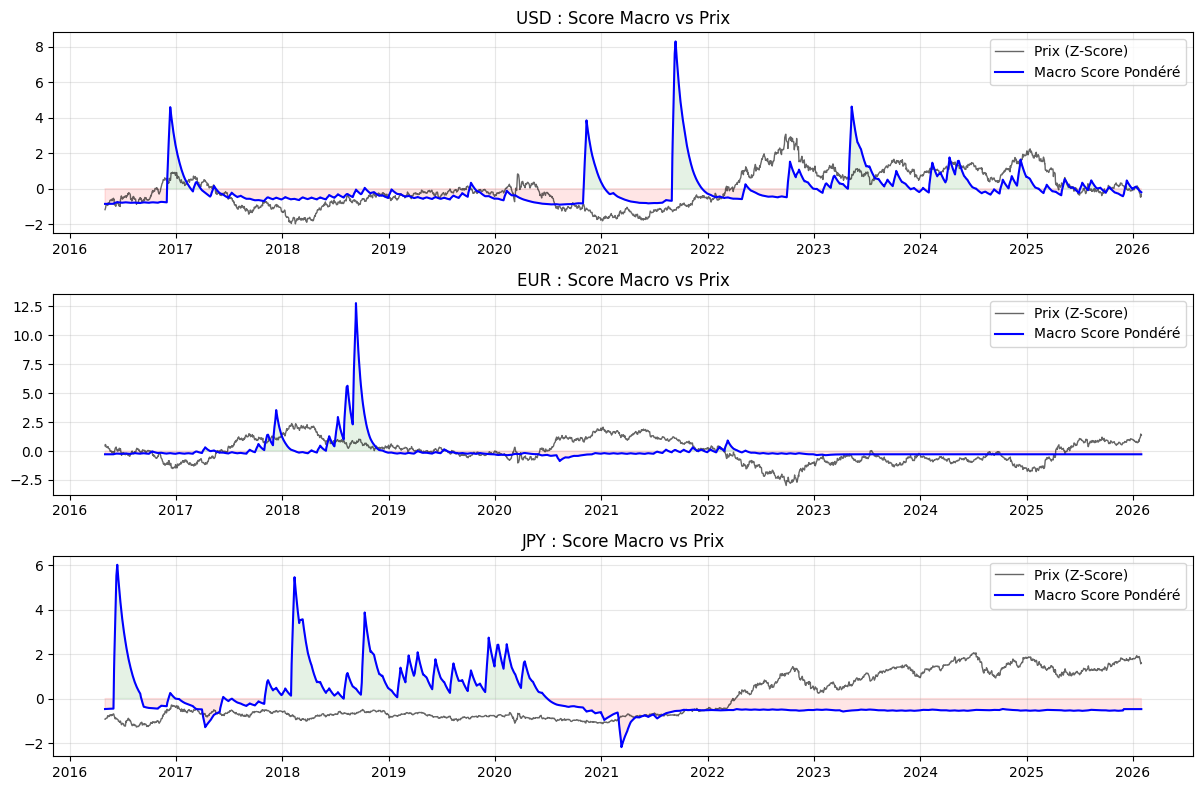


--- Corrélation Score Final vs Prix (10j Forward) ---


In [ ]:
def get_optimized_weights(df_calibrated):
    weights_dict = {}
    
    # On ne garde que ce qui performe mieux que le hasard (> 50%)
    df_clean = df_calibrated[df_calibrated['Accuracy'] > 0.50].copy()
    
    # Métrique de performance : Excess Accuracy (Combien de % au-dessus de 50%)
    df_clean['Signal_Strength'] = df_clean['Accuracy'] - 0.50
    
    for zone in df_clean['Zone'].unique():
        zone_data = df_clean[df_clean['Zone'] == zone]
        total_strength = zone_data['Signal_Strength'].sum()
        
        if total_strength == 0: continue
            
        # Normalisation pour que la somme des poids fasse 1.0 (100%)
        w = dict(zip(zone_data['Indicator'], zone_data['Signal_Strength'] / total_strength))
        weights_dict[zone] = w
        
    return weights_dict


In [ ]:
def calculate_weighted_final_score(hist_scores, weights_dict):
    series_list = []

    for zone, df in hist_scores.items():
        if zone not in weights_dict: continue
        
        w = weights_dict[zone]
        weighted_sum = np.zeros(len(df))
        valid = False
        
        for ind, weight in w.items():
            if ind in df.columns:
                weighted_sum += df[ind].values * weight
                valid = True
        
        if valid:
            s = pd.Series(weighted_sum, index=df.index, name=zone)
            series_list.append(s)

    if series_list:
        final_scores = pd.concat(series_list, axis=1).sort_index()
        return final_scores.fillna(0)
    else:
        return pd.DataFrame()


In [ ]:
weights = get_optimized_weights(df_importance)

for z, w in weights.items():
    print(f"{z} : { {k: round(v, 2) for k, v in w.items()} }")

df_final_weighted = calculate_weighted_final_score(dfs, weights)

zones_to_plot = ['USD', 'EUR', 'JPY'] # Sélection

plt.figure(figsize=(12, 8))

for i, zone in enumerate(zones_to_plot):
    if zone not in df_final_weighted.columns: continue
    
    ticker_map = {'USD': 'DX-Y.NYB', 'EUR': 'EURUSD=X', 'JPY': 'JPY=X'}
    price = yf.download(ticker_map[zone], start=df_final_weighted.index[0], progress=False)['Close']
    if isinstance(price, pd.DataFrame): price = price.iloc[:,0]
    

    comp_df = pd.DataFrame({'Score': df_final_weighted[zone], 'Price': price}).dropna()
    comp_df = (comp_df - comp_df.mean()) / comp_df.std()
    
    plt.subplot(len(zones_to_plot), 1, i+1)
    plt.plot(comp_df.index, comp_df['Price'], label='Prix (Z-Score)', color='black', alpha=0.6, linewidth=1)
    plt.plot(comp_df.index, comp_df['Score'], label='Macro Score Pondéré', color='blue', linewidth=1.5)
    
    # Coloration des zones
    plt.fill_between(comp_df.index, comp_df['Score'], 0, where=(comp_df['Score'] > 0), color='green', alpha=0.1)
    plt.fill_between(comp_df.index, comp_df['Score'], 0, where=(comp_df['Score'] < 0), color='red', alpha=0.1)
    
    plt.title(f"{zone} : Score Macro vs Prix")
    plt.legend()
    plt.grid(True, alpha=0.3)
        

plt.tight_layout()
plt.show()



NameError: name 'get_optimized_weights' is not defined